In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import pandas as pd
import matplotlib.pyplot as plt

## Task 1

In [2]:
print("PyTorch version:", torch.__version__)
print("torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.0+cu130
torchvision version: 0.29.0+cu130
CUDA available: True
Using device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


## Task 2

In [3]:
transform = transforms.ToTensor()
full_train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)
train_dataset, val_dataset = random_split(full_train_dataset, [50000, 10000], generator=torch.Generator().manual_seed(42))

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(full_train_dataset)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Classes:", full_train_dataset.classes)
print("Training batches per epoch:", len(train_loader))

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()
Training images: 50000
Validation images: 10000
Test images: 10000
Classes: ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
Training batches per epoch: 1563


## Task 3

Images tensor size: torch.Size([32, 1, 28, 28])


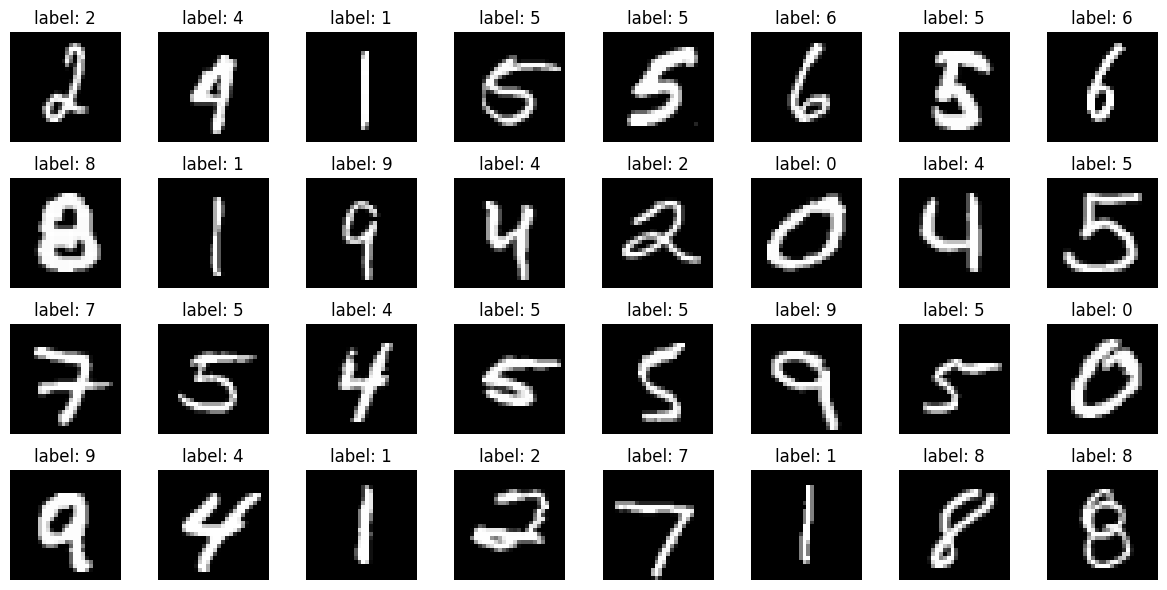

In [4]:
images, labels = next(iter(train_loader))
print("Images tensor size:", images.shape)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for ax, img, label in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"label: {label.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 4

In [5]:
class SimpleNet(nn.Module):

    def __init__(self, hidden_size=128):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, hidden_size)
        self.fc2 = nn.Linear(hidden_size, 10)

    def forward(self, x):
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

net = SimpleNet()
print(net)
print("Trainable parameters:", sum(p.numel() for p in net.parameters()))
images, labels = next(iter(train_loader))

print("Before flatten:", images.shape)
print("After flatten:", torch.flatten(images, 1).shape)
print("Network output:", net(images).shape)

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 101770
Before flatten: torch.Size([32, 1, 28, 28])
After flatten: torch.Size([32, 784])
Network output: torch.Size([32, 10])


## Task 5

In [6]:
def evaluate(net, loader):
    criterion = nn.CrossEntropyLoss()
    net.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total


def train(net, train_loader, epochs=5, lr=0.01, momentum=0.9, val_loader=None, log_every=500, verbose=True):
    net.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)
    batch_losses = []
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        net.train()
        running_loss, correct, total = 0.0, 0, 0
        for batch, (images, labels) in enumerate(train_loader, 1):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = net(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())
            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
            if verbose and batch % log_every == 0:
                print(f"Epoch {epoch}/{epochs}, Batch {batch}/{len(train_loader)}, loss: {loss.item():.4f}, accuracy: {100 * correct / total:.2f}%")

        history["train_loss"].append(running_loss / total)
        history["train_acc"].append(100 * correct / total)
        msg = f"==> Epoch {epoch}: train loss {history['train_loss'][-1]:.4f}, train accuracy {history['train_acc'][-1]:.2f}%"
        if val_loader is not None:
            val_loss, val_acc = evaluate(net, val_loader)
            history["val_loss"].append(val_loss)
            history["val_acc"].append(val_acc)
            msg += f", val loss {val_loss:.4f}, val accuracy {val_acc:.2f}%"
        if verbose:
            print(msg)

    return batch_losses, history

## Task 6

In [7]:
torch.manual_seed(42)
net = SimpleNet(hidden_size=128)
epochs = 5
batch_losses, history = train(net, train_loader, epochs=epochs, lr=0.01, momentum=0.9, val_loader=val_loader)

Epoch 1/5, Batch 500/1563, loss: 0.1050, accuracy: 82.19%
Epoch 1/5, Batch 1000/1563, loss: 0.2529, accuracy: 86.82%
Epoch 1/5, Batch 1500/1563, loss: 0.1850, accuracy: 88.81%
==> Epoch 1: train loss 0.3833, train accuracy 88.97%, val loss 0.2273, val accuracy 93.46%
Epoch 2/5, Batch 500/1563, loss: 0.2015, accuracy: 94.49%
Epoch 2/5, Batch 1000/1563, loss: 0.1642, accuracy: 94.67%
Epoch 2/5, Batch 1500/1563, loss: 0.1605, accuracy: 94.86%
==> Epoch 2: train loss 0.1781, train accuracy 94.92%, val loss 0.1669, val accuracy 95.23%
Epoch 3/5, Batch 500/1563, loss: 0.1205, accuracy: 96.18%
Epoch 3/5, Batch 1000/1563, loss: 0.1891, accuracy: 96.37%
Epoch 3/5, Batch 1500/1563, loss: 0.2300, accuracy: 96.39%
==> Epoch 3: train loss 0.1257, train accuracy 96.40%, val loss 0.1368, val accuracy 95.90%
Epoch 4/5, Batch 500/1563, loss: 0.0401, accuracy: 97.14%
Epoch 4/5, Batch 1000/1563, loss: 0.0803, accuracy: 97.18%
Epoch 4/5, Batch 1500/1563, loss: 0.1474, accuracy: 97.12%
==> Epoch 4: train l

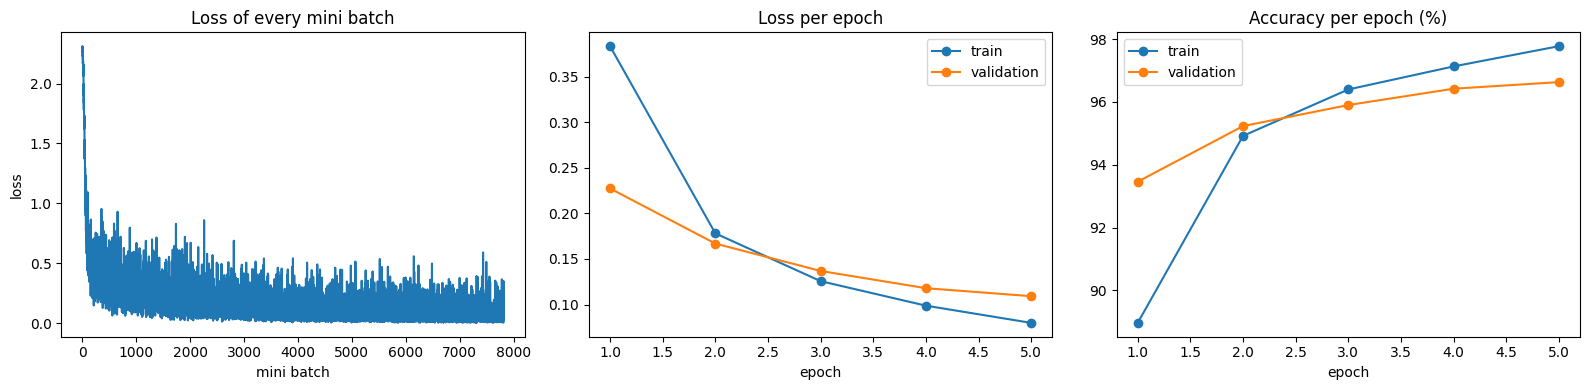

,train_loss,train_acc,val_loss,val_acc
1,0.3833,88.966,0.2273,93.46
2,0.1781,94.918,0.1669,95.23
3,0.1257,96.396,0.1368,95.90
4,0.0988,97.130,0.1179,96.42
5,0.0799,97.774,0.1092,96.63


In [14]:
def plot_training(batch_losses, history):
    epochs = range(1, len(history["train_loss"]) + 1)
    __, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(batch_losses)
    axes[0].set_title("Loss of every mini batch")
    axes[0].set_xlabel("mini batch")
    axes[0].set_ylabel("loss")
    axes[1].plot(epochs, history["train_loss"], marker="o", label="train")
    axes[1].plot(epochs, history["val_loss"], marker="o", label="validation")
    axes[1].set_title("Loss per epoch")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    axes[2].plot(epochs, history["train_acc"], marker="o", label="train")
    axes[2].plot(epochs, history["val_acc"], marker="o", label="validation")
    axes[2].set_title("Accuracy per epoch (%)")
    axes[2].set_xlabel("epoch")
    axes[2].legend()
    plt.tight_layout()
    plt.show()

plot_training(batch_losses, history)
pd.DataFrame(history, index=range(1, epochs + 1)).round(4)

## Task 7

Test loss: 0.0951, test accuracy: 97.22%
True labels: [7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5]
Predictions: [7, 2, 1, 0, 4, 1, 4, 9, 6, 9, 0, 6, 9, 0, 1, 5]
Correct: 31 out of 32


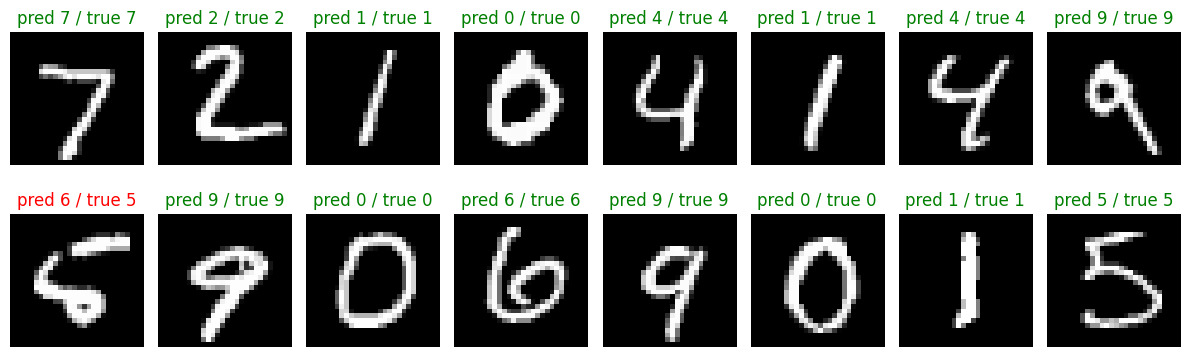

In [15]:
test_loss, test_acc = evaluate(net, test_loader)
print(f"Test loss: {test_loss:.4f}, test accuracy: {test_acc:.2f}%")

net.eval()
test_images, test_labels = next(iter(test_loader))
with torch.no_grad():
    outputs = net(test_images.to(device))
preds = outputs.argmax(1).cpu()
print("True labels:", test_labels[:16].tolist())
print("Predictions:", preds[:16].tolist())
print("Correct:", (preds == test_labels).sum().item(), "out of", len(test_labels))

fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label, pred in zip(axes.flat, test_images, test_labels, preds):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"pred {pred.item()} / true {label.item()}", color="green" if pred == label else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

Misclassified test images: 278 out of 10000


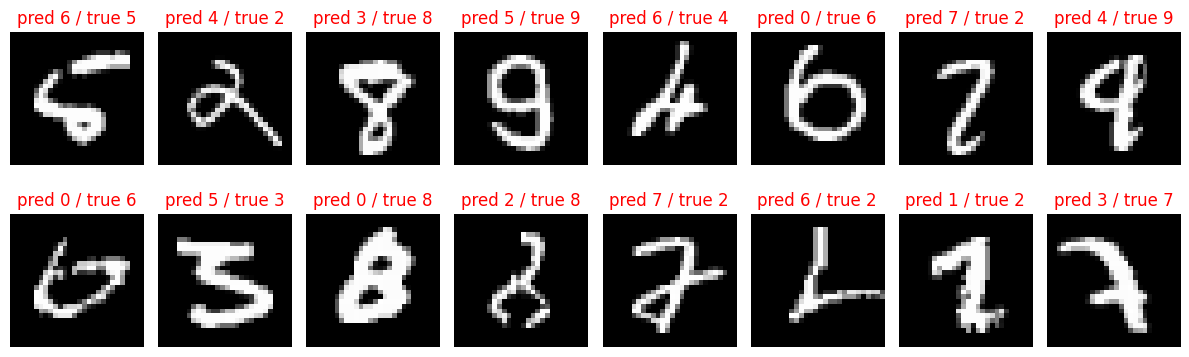

In [16]:
wrong = []
with torch.no_grad():
    for images, labels in test_loader:
        preds = net(images.to(device)).argmax(1).cpu()
        for img, label, pred in zip(images, labels, preds):
            if pred != label:
                wrong.append((img, label.item(), pred.item()))
print("Misclassified test images:", len(wrong), "out of", len(test_dataset))

fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, (img, label, pred) in zip(axes.flat, wrong):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"pred {pred} / true {label}", color="red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 8

In [17]:
tune_epochs = 3
results = []
for lr in [0.001, 0.01, 0.1]:
    for momentum in [0.0, 0.5, 0.9]:
        torch.manual_seed(42)
        model = SimpleNet(hidden_size=128)
        _, h = train(model, train_loader, epochs=tune_epochs, lr=lr, momentum=momentum, val_loader=val_loader, verbose=False)
        results.append({"lr": lr, "momentum": momentum, "train_loss": h["train_loss"][-1], "val_loss": h["val_loss"][-1], "val_acc": h["val_acc"][-1]})
        print(f"lr={lr}, momentum={momentum}: train loss {h['train_loss'][-1]:.4f}, val loss {h['val_loss'][-1]:.4f}, val accuracy {h['val_acc'][-1]:.2f}%")

param_results = pd.DataFrame(results).sort_values("val_acc", ascending=False)
display(param_results.round(4))
best_lr = float(param_results.iloc[0]["lr"])
best_momentum = float(param_results.iloc[0]["momentum"])
print("Best learning rate:", best_lr, "best momentum:", best_momentum)

lr=0.001, momentum=0.0: train loss 1.1968, val loss 1.0251, val accuracy 80.29%
lr=0.001, momentum=0.5: train loss 0.6921, val loss 0.6105, val accuracy 85.72%
lr=0.001, momentum=0.9: train loss 0.3380, val loss 0.3304, val accuracy 90.46%
lr=0.01, momentum=0.0: train loss 0.3376, val loss 0.3315, val accuracy 90.33%
lr=0.01, momentum=0.5: train loss 0.2776, val loss 0.2744, val accuracy 91.93%
lr=0.01, momentum=0.9: train loss 0.1257, val loss 0.1368, val accuracy 95.90%
lr=0.1, momentum=0.0: train loss 0.1243, val loss 0.1464, val accuracy 95.59%
lr=0.1, momentum=0.5: train loss 0.0867, val loss 0.1165, val accuracy 96.40%
lr=0.1, momentum=0.9: train loss 0.1295, val loss 0.1626, val accuracy 95.89%


,lr,momentum,train_loss,val_loss,val_acc
7,0.100,0.5,0.0867,0.1165,96.40
5,0.010,0.9,0.1257,0.1368,95.90
8,0.100,0.9,0.1295,0.1626,95.89
6,0.100,0.0,0.1243,0.1464,95.59
4,0.010,0.5,0.2776,0.2744,91.93
2,0.001,0.9,0.3380,0.3304,90.46
3,0.010,0.0,0.3376,0.3315,90.33
1,0.001,0.5,0.6921,0.6105,85.72
0,0.001,0.0,1.1968,1.0251,80.29


Best learning rate: 0.1 best momentum: 0.5


In [18]:
class MLP(nn.Module):
    def __init__(self, hidden_sizes):
        super().__init__()
        layers = []
        in_features = 28 * 28
        for h in hidden_sizes:
            layers += [nn.Linear(in_features, h), nn.ReLU()]
            in_features = h
        layers.append(nn.Linear(in_features, 10))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(torch.flatten(x, 1))

architectures = [[32], [64], [128], [256], [512], [256, 128], [512, 256], [512, 256, 128], [512, 256, 128, 64]]
results = []
for hidden in architectures:
    torch.manual_seed(42)
    model = MLP(hidden)
    _, h = train(model, train_loader, epochs=tune_epochs, lr=best_lr, momentum=best_momentum, val_loader=val_loader, verbose=False)
    results.append({"hidden layers": str(hidden), "layers": len(hidden), "parameters": sum(p.numel() for p in model.parameters()),"train_loss": h["train_loss"][-1], "val_loss": h["val_loss"][-1], "val_acc": h["val_acc"][-1]})
    print(f"hidden layers {hidden}: train loss {h['train_loss'][-1]:.4f}, val loss {h['val_loss'][-1]:.4f}, val accuracy {h['val_acc'][-1]:.2f}%")

arch_results = pd.DataFrame(results).sort_values("val_acc", ascending=False)
display(arch_results.round(4))
best_hidden = architectures[arch_results.index[0]]
print("Best architecture: hidden layers", best_hidden)

hidden layers [32]: train loss 0.1391, val loss 0.1693, val accuracy 95.14%
hidden layers [64]: train loss 0.1043, val loss 0.1350, val accuracy 95.93%
hidden layers [128]: train loss 0.0867, val loss 0.1165, val accuracy 96.40%
hidden layers [256]: train loss 0.0800, val loss 0.0987, val accuracy 97.09%
hidden layers [512]: train loss 0.0752, val loss 0.1096, val accuracy 96.69%
hidden layers [256, 128]: train loss 0.0731, val loss 0.1105, val accuracy 96.57%
hidden layers [512, 256]: train loss 0.0683, val loss 0.0946, val accuracy 97.16%
hidden layers [512, 256, 128]: train loss 0.0748, val loss 0.1215, val accuracy 96.42%
hidden layers [512, 256, 128, 64]: train loss 0.0805, val loss 0.1351, val accuracy 96.21%


,hidden layers,layers,parameters,train_loss,val_loss,val_acc
6,"[512, 256]",2,535818,0.0683,0.0946,97.16
3,[256],1,203530,0.0800,0.0987,97.09
4,[512],1,407050,0.0752,0.1096,96.69
5,"[256, 128]",2,235146,0.0731,0.1105,96.57
7,"[512, 256, 128]",3,567434,0.0748,0.1215,96.42
2,[128],1,101770,0.0867,0.1165,96.40
8,"[512, 256, 128, 64]",4,575050,0.0805,0.1351,96.21
1,[64],1,50890,0.1043,0.1350,95.93
0,[32],1,25450,0.1391,0.1693,95.14


Best architecture: hidden layers [512, 256]


Epoch 1/10, Batch 1563/1563, loss: 0.0138, accuracy: 91.34%
==> Epoch 1: train loss 0.2868, train accuracy 91.34%, val loss 0.1500, val accuracy 95.39%
Epoch 2/10, Batch 1563/1563, loss: 0.0209, accuracy: 96.96%
==> Epoch 2: train loss 0.1004, train accuracy 96.96%, val loss 0.1028, val accuracy 96.69%
Epoch 3/10, Batch 1563/1563, loss: 0.0127, accuracy: 97.83%
==> Epoch 3: train loss 0.0683, train accuracy 97.83%, val loss 0.0946, val accuracy 97.16%
Epoch 4/10, Batch 1563/1563, loss: 0.0845, accuracy: 98.46%
==> Epoch 4: train loss 0.0482, train accuracy 98.46%, val loss 0.0931, val accuracy 97.25%
Epoch 5/10, Batch 1563/1563, loss: 0.0004, accuracy: 98.94%
==> Epoch 5: train loss 0.0329, train accuracy 98.94%, val loss 0.0761, val accuracy 97.88%
Epoch 6/10, Batch 1563/1563, loss: 0.0561, accuracy: 99.20%
==> Epoch 6: train loss 0.0254, train accuracy 99.20%, val loss 0.0853, val accuracy 97.65%
Epoch 7/10, Batch 1563/1563, loss: 0.0011, accuracy: 99.43%
==> Epoch 7: train loss 0.01

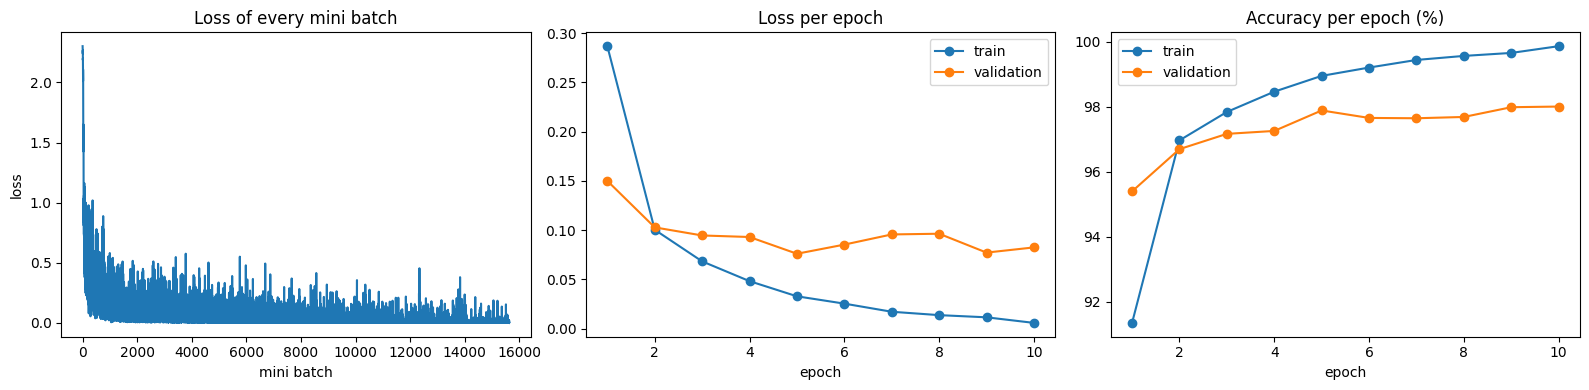

Best model: hidden layers [512, 256], lr=0.1, momentum=0.5, 10 epochs
Lowest train loss: 0.0059
Highest validation accuracy: 98.00%
Test loss: 0.0679, test accuracy: 98.18%
Task 6 baseline for comparison: test loss 0.0951, test accuracy 97.22%


In [19]:
torch.manual_seed(42)
best_net = MLP(best_hidden)
best_batch_losses, best_history = train(best_net, train_loader, epochs=10, lr=best_lr, momentum=best_momentum, val_loader=val_loader, log_every=len(train_loader))
plot_training(best_batch_losses, best_history)

best_test_loss, best_test_acc = evaluate(best_net, test_loader)
print(f"Best model: hidden layers {best_hidden}, lr={best_lr}, momentum={best_momentum}, 10 epochs")
print(f"Lowest train loss: {min(best_history['train_loss']):.4f}")
print(f"Highest validation accuracy: {max(best_history['val_acc']):.2f}%")
print(f"Test loss: {best_test_loss:.4f}, test accuracy: {best_test_acc:.2f}%")
print(f"Task 6 baseline for comparison: test loss {test_loss:.4f}, test accuracy {test_acc:.2f}%")